# Run an Experiment

Config-first workflow:

1. Pick an experiment id from `configs/experiments/`.
2. Call `run_experiment(cfg)`. That's it.

To add a new experiment, drop a YAML into `configs/experiments/` — no code change.
Every run snapshots its fully-resolved config into `data/processed/xgboost_experiments/<id>/config_snapshot.json` so results are reproducible.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import load_config
from src.experiments.runner import run_experiment
from src.viz import make_all_plots


/Users/jaidonfroggatt-morton/miniforge3/envs/msc-dissertation-mots1-v2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Pick one and load it. Change this single line to switch experiments.
ACTIVE = 'exp_035_pa_chemistry_standardised'  # CHANGE THIS
cfg = load_config(ACTIVE)

print(f'Loaded: {cfg.id}')
print(f'  description : {cfg.description}')
print(f'  hypothesis  : {cfg.hypothesis}')
print(f'  sections    : {cfg.run.sections}')
print(f'  trials      : {cfg.xgb.n_trials}')
print(f'  engineered  : {cfg.features.use_engineered}')
print(f'  results dir : {cfg.results_dir}') 

Loaded: exp_035_pa_chemistry_standardised
  description : Standardised headline run under the supervisor's chemistry-based split methodology (May 2026 meeting).  Holds out two entire chemistries (F1_Triton and F2_Tego) for testing; uses the fixed chemistry split stored under data/processed/splits_chemistry/default/.  All five physics oracles remain supported and CY5 is the default per its empirical advantage in exp_030.  Augmentation is applied to training rows only; the test rows are never fitted or augmented.
This is the first run that should be cited as the dissertation's headline result, with exp_036 (LOO across all 12 chemistries) and exp_037 (few-shot variants) providing the generalisation envelope.

  hypothesis  : Holding out two entire chemistries is materially stricter than the Composite_Mix_ID-grouped split used in exp_030 — the model has never seen the dispersant×formulation combinations in test rows.  Expected test R² is below exp_030's 0.741, with the gap quantifying how 

## Run

`run_experiment` loads splits, fits physics parameters for every model, and dispatches to each section listed in `cfg.run.sections`. Each run gets a unique directory under `data/processed/xgboost_experiments/` named `{experiment_id}_{YYYYMMDD_HHMMSS}`, so re-running the same config never overwrites previous results. The path is available as `results.results_dir`.

In [3]:
results = run_experiment(cfg)

ACTIVE EXPERIMENT: exp_035_pa_chemistry_standardised
Description : Standardised headline run under the supervisor's chemistry-based split methodology (May 2026 meeting).  Holds out two entire chemistries (F1_Triton and F2_Tego) for testing; uses the fixed chemistry split stored under data/processed/splits_chemistry/default/.  All five physics oracles remain supported and CY5 is the default per its empirical advantage in exp_030.  Augmentation is applied to training rows only; the test rows are never fitted or augmented.
This is the first run that should be cited as the dissertation's headline result, with exp_036 (LOO across all 12 chemistries) and exp_037 (few-shot variants) providing the generalisation envelope.

Hypothesis  : Holding out two entire chemistries is materially stricter than the Composite_Mix_ID-grouped split used in exp_030 — the model has never seen the dispersant×formulation combinations in test rows.  Expected test R² is below exp_030's 0.741, with the gap quantifyi

## Inspect results

`results` is an `ExperimentResults`: a dict of `SectionResult` objects keyed by section name. Every section has `model_summary`, `per_target`, and (optionally) `predictions` DataFrames.

In [4]:
for name, section in results.sections.items():
    print(f'--- {name} ---')
    display(section.sorted_by_r2().head())

print('Best (baseline/sweep/loo, first hit):', results.best())

--- physics_augmented ---


,variant,physics_oracle,learner,model_name,model_key,test_r2,test_r2_log,test_mae,test_rmse,n_test,n_aug_points,physics_model
0,cy5__xgb,cy5,xgb,cy5__xgb,cy5__xgb,0.656951,0.790865,11.039685,29.012230,171,30,cy5
1,williamson__xgb,williamson,xgb,williamson__xgb,williamson__xgb,0.647858,0.790378,11.156205,29.394192,171,30,williamson
2,sisko__xgb,sisko,xgb,sisko__xgb,sisko__xgb,0.645785,0.793037,11.244852,29.480581,171,30,sisko
3,constrained_cy__xgb,constrained_cy,xgb,constrained_cy__xgb,constrained_cy__xgb,0.644320,0.796835,11.184372,29.541493,171,30,constrained_cy
4,power_law__xgb,power_law,xgb,power_law__xgb,power_law__xgb,0.641849,0.798606,11.249077,29.643915,171,30,power_law


Best (baseline/sweep/loo, first hit): None


## Plots

In [5]:
if results.results_dir is None:
    print("Run was not persisted (persist=False) — no results directory to plot into.")
else:
    saved = make_all_plots(results, results.results_dir)
    for p in saved:
        print(p)

/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_035_pa_chemistry_standardised_20260514_163803/physics_augmented_model_comparison.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_035_pa_chemistry_standardised_20260514_163803/physics_augmented_per_target_r2_heatmap.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_035_pa_chemistry_standardised_20260514_163803/physics_augmented_variants.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_035_pa_chemistry_standardised_20260514_163803/physics_augmented_constrained_cy__xgb_predicted_vs_actual.png
/Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/proc

## Physics-augmented dataset visualisation

Only rendered when the active experiment uses the `physics_augmented` section.

* **Augmented dataset overview** — all training points (measured + augmented) on log-log axes, one subplot per physics oracle.  Shows how the 30 log-uniform samples per row fill the shear-rate space.
* **Sample flow curves** — 12 randomly sampled training rows showing the oracle-fitted curve (line) alongside the three measured viscosities (circles) on log-log axes.

Saved: /Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_035_pa_chemistry_standardised_20260514_163803/augmented_dataset_overview.png
Saved: /Users/jaidonfroggatt-morton/Documents/Warwick/Dissertation/MOTS.1/msc-dissertation-project-v2/data/processed/xgboost_experiments/exp_035_pa_chemistry_standardised_20260514_163803/augmented_sample_curves.png


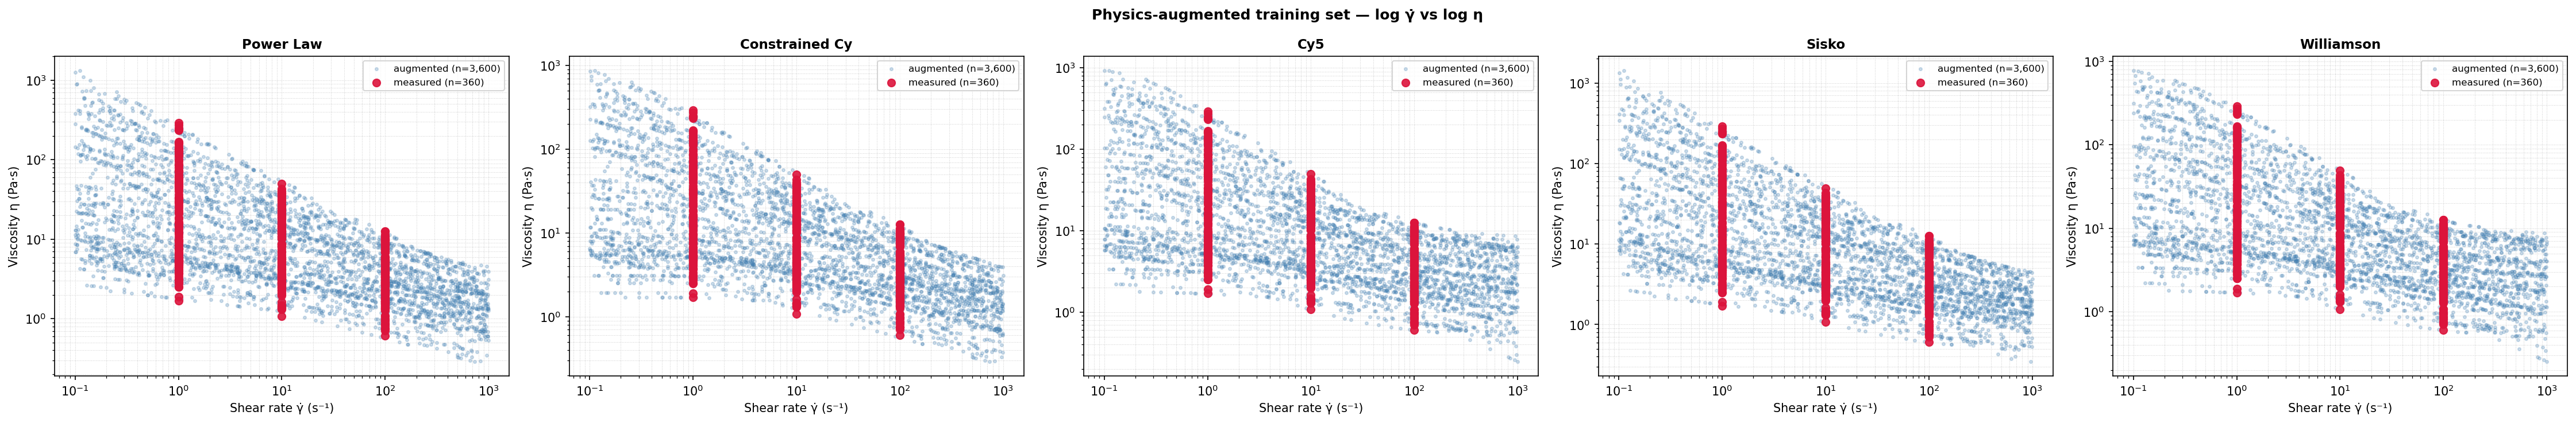

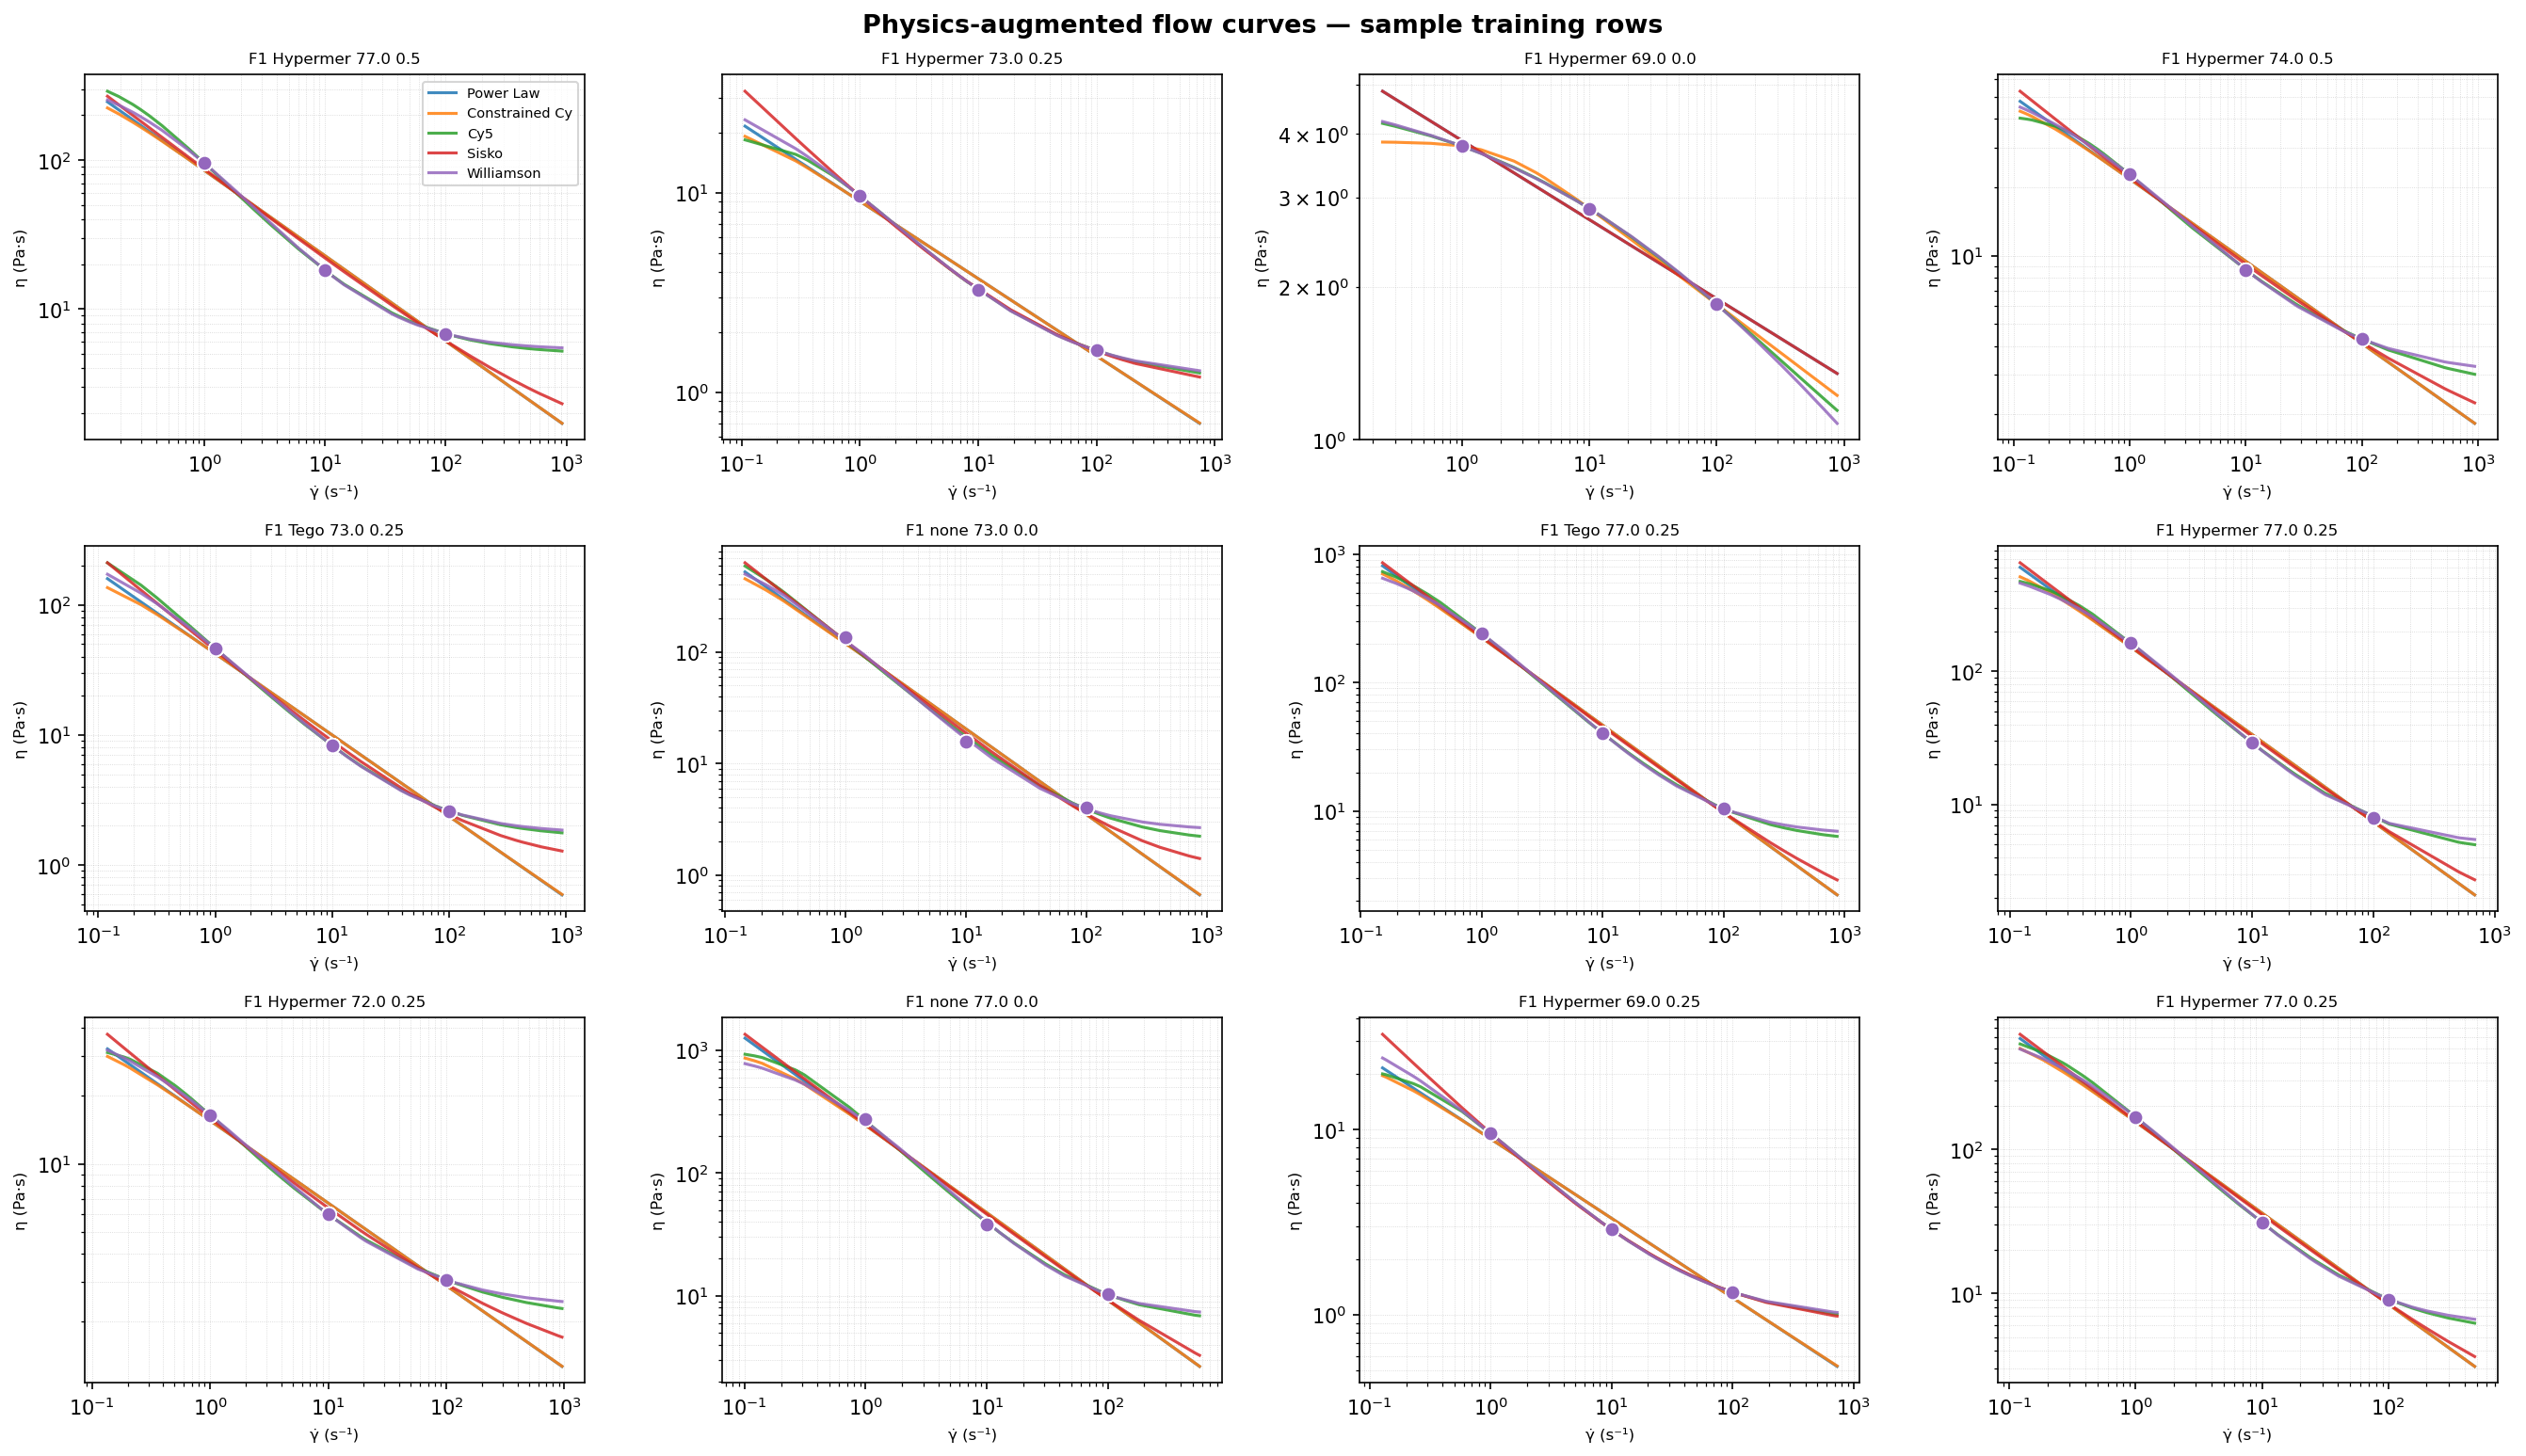

In [6]:
from IPython.display import Image, display as ipy_display

if 'physics_augmented' not in cfg.run.sections:
    print("Not a physics_augmented experiment — skip this cell.")
else:
    from src.data.splits import load_splits
    from src.physics_augmented.data import build_augmented_split
    from src.viz import plot_augmented_dataset_overview, plot_augmented_sample_curves

    pa_cfg = cfg.physics_augmented
    train_df, test_df = load_splits(cfg)

    splits = {}
    for model_key in pa_cfg.models:
        splits[model_key] = build_augmented_split(
            train_df=train_df,
            test_df=test_df,
            cfg=cfg,
            model_key=model_key,
            n_aug_points=int(pa_cfg.n_aug_points),
            shear_range=tuple(pa_cfg.shear_range),
            log_uniform=bool(pa_cfg.log_uniform_gamma),
            measured_weight=float(pa_cfg.measured_weight),
            seed=cfg.seed,
        )

    out_dir = results.results_dir or cfg.results_dir
    overview_path = plot_augmented_dataset_overview(splits, out_dir)
    curves_path   = plot_augmented_sample_curves(splits, out_dir, n_sample=12)

    print(f"Saved: {overview_path}")
    print(f"Saved: {curves_path}")
    ipy_display(Image(str(overview_path)))
    ipy_display(Image(str(curves_path)))

## Compare completed experiments

The `experiment_manifest.json` at the top of `data/processed/xgboost_experiments/` accumulates every run across the project.

In [7]:
import json
import pandas as pd

manifest_path = cfg.experiments_root_path / 'experiment_manifest.json'
if manifest_path.exists():
    runs = json.loads(manifest_path.read_text())['runs']
    df = pd.json_normalize(runs)
    cols = ['run_id', 'experiment_id', 'description', 'sections_run',
            'best.model_name', 'best.test_r2', 'duration_seconds', 'created_at_utc', 'notes']
    display(df[[c for c in cols if c in df.columns]])
else:
    print('No manifest yet. Run an experiment first.')

,run_id,experiment_id,description,sections_run,best.model_name,best.test_r2,duration_seconds,created_at_utc,notes
0,exp_035_pa_chemistry_standardised_20260514_163803,exp_035_pa_chemistry_standardised,Standardised headline run under the supervisor...,[physics_augmented],NaN,NaN,3.2,2026-05-14T16:38:03.076273+00:00,
1,exp_033_pa_no_augmentation_20260512_144740,exp_033_pa_no_augmentation,No-augmentation baseline for the physics-augme...,[physics_augmented],NaN,NaN,0.2,2026-05-12T14:47:40.395132+00:00,
2,exp_030_pa_log_target_aug_sweep_0200pts_202605...,exp_030_pa_log_target_aug_sweep_0200pts,Physics-augmented training — log1p target tran...,[physics_augmented],NaN,NaN,3.1,2026-05-12T14:04:09.033943+00:00,
3,exp_030_pa_log_target_aug_sweep_0500pts_202605...,exp_030_pa_log_target_aug_sweep_0500pts,Physics-augmented training — log1p target tran...,[physics_augmented],NaN,NaN,3.6,2026-05-12T14:02:35.590927+00:00,
4,exp_030_pa_log_target_aug_sweep_0300pts_202605...,exp_030_pa_log_target_aug_sweep_0300pts,Physics-augmented training — log1p target tran...,[physics_augmented],NaN,NaN,3.3,2026-05-12T14:02:31.500003+00:00,
...,...,...,...,...,...,...,...,...,...
81,exp_010_loo_only_20260421_152239,exp_010_loo_only,Leave-one-out generalisability evaluation (row...,[loo],Power Law,0.647151,264.2,2026-04-21T15:22:39.748376+00:00,
82,exp_004_trials_20_raw_20260421_145230,exp_004_trials_20_raw,Higher trials + raw features.,[baseline],Power Law,0.478763,68.5,2026-04-21T14:52:30.448196+00:00,
83,exp_003_raw_only_20260421_145112,exp_003_raw_only,Raw features only (no engineered features).,[baseline],Power Law,0.491317,30.6,2026-04-21T14:51:12.802008+00:00,
84,exp_002_trials_20_20260421_144927,exp_002_trials_20,Higher trial budget: 20 Optuna trials.,[baseline],Power Law,0.433388,70.1,2026-04-21T14:49:27.551810+00:00,


## Annotate a run

Add a free-text note to any completed run without re-running it.
Notes are saved into the manifest and each run's `metadata.json`.

```python
from src.experiments.results import annotate_run

annotate_run(
    run_id='<paste run_id from the table above>',
    note='Your observation here — e.g. Power Law best, CY5 overfit.',
    experiments_root=cfg.experiments_root_path,
)
```

Re-run the comparison cell above to see the note in the table.

In [8]:
from src.experiments.results import annotate_run

# Replace the run_id and note, then run this cell.
"""
annotate_run(
     run_id='exp_005_log_target_20260501_142410',
     note='attempted run without engineered features, to see if it would help with the log target. It did not.',
     experiments_root=cfg.experiments_root_path,
 )
"""

"\nannotate_run(\n     run_id='exp_005_log_target_20260501_142410',\n     note='attempted run without engineered features, to see if it would help with the log target. It did not.',\n     experiments_root=cfg.experiments_root_path,\n )\n"